# XGBoost Only: Lag Features vs Lag + Rolling Statistics

This notebook keeps the precipitation forecast pipeline focused on XGBoost only. It compares two feature sets under the same Box-Cox preprocessing and the same randomized hyperparameter search:

1. Lag features only
2. Lag features plus 7-day and 14-day rolling mean and standard deviation features

The goal is to see whether the rolling summary features improve validation and test performance before settling on a final XGBoost setup.

In [19]:
# Importing required libraries
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from scipy.special import inv_boxcox
from scipy.stats import boxcox
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import ParameterSampler

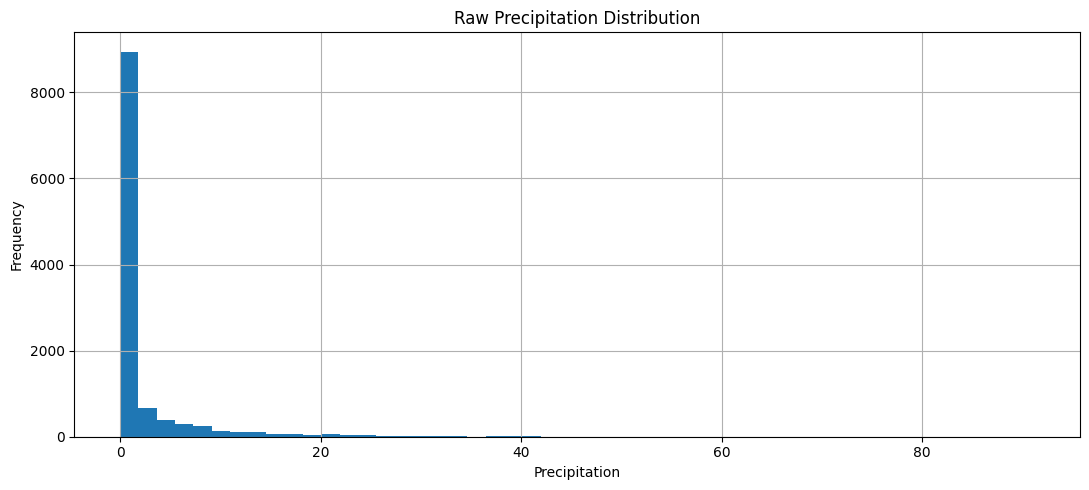

,PRCP
DATE,
1990-01-01,0.0
1990-01-02,0.0
1990-01-03,0.0


In [20]:
# Load the rainfall dataset
csv_candidates = ['content/2619492.csv', '2619492.csv', 'Data/2619492.csv']
csv_path = next((p for p in csv_candidates if Path(p).exists()), None)
if csv_path is None:
    raise FileNotFoundError('Could not find 2619492.csv in expected paths.')

rainfall = pd.read_csv(csv_path)
rainfall['DATE'] = pd.to_datetime(rainfall['DATE'], dayfirst=True)
rainfall = rainfall.set_index('DATE')

plt.figure(figsize=(11, 5))
rainfall['PRCP'].hist(bins=50)
plt.title('Raw Precipitation Distribution')
plt.xlabel('Precipitation')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

rainfall.head(3)

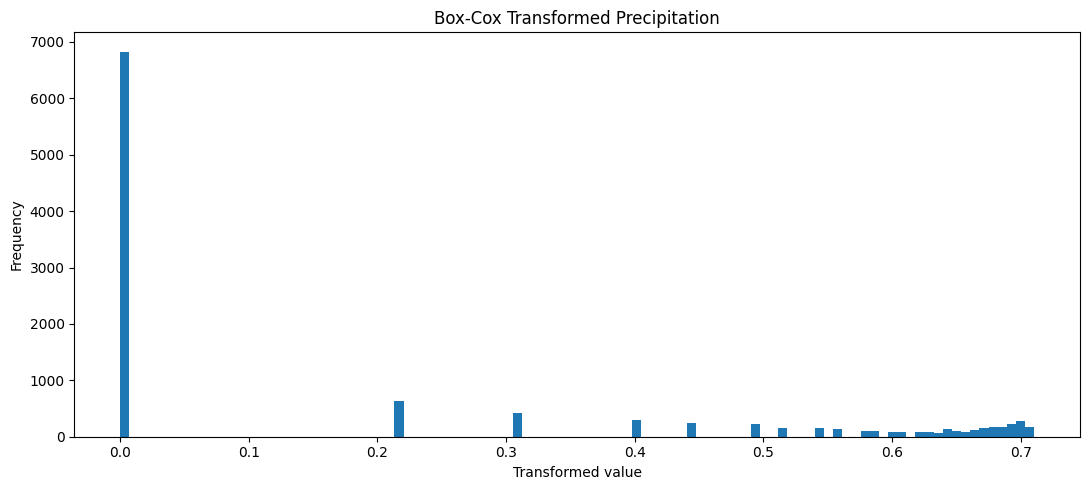

In [21]:
# Box-Cox transform the precipitation series
def boxcox1p(data):
    shifted = data + 1
    transformed, lambda_value = boxcox(shifted)
    return transformed, lambda_value

def inv_boxcox1p(transformed, lambda_value):
    return inv_boxcox(transformed, lambda_value) - 1

rain_data_bc, lam_value = boxcox1p(rainfall['PRCP'].to_numpy())

plt.figure(figsize=(11, 5))
plt.hist(rain_data_bc, bins=100)
plt.title('Box-Cox Transformed Precipitation')
plt.xlabel('Transformed value')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [22]:
# Feature engineering helpers
def build_xgb_feature_matrix(series, lag_window=70, rolling_windows=(7, 14), include_rolling=False):
    values = np.asarray(series, dtype=float)
    start_index = max(lag_window, max(rolling_windows, default=lag_window))
    x_rows = []
    y_rows = []
    target_indices = []

    for target_index in range(start_index, len(values)):
        lag_slice = values[target_index - lag_window:target_index]
        features = list(lag_slice)

        if include_rolling:
            for window in rolling_windows:
                trailing = values[target_index - window:target_index]
                features.append(float(np.mean(trailing)))
                features.append(float(np.std(trailing, ddof=0)))

        x_rows.append(features)
        y_rows.append(values[target_index])
        target_indices.append(target_index)

    x_array = np.asarray(x_rows, dtype=float)
    y_array = np.asarray(y_rows, dtype=float)
    target_indices = np.asarray(target_indices, dtype=int)

    lag_feature_names = [f'lag_{lag_window - i}' for i in range(lag_window)]
    if include_rolling:
        rolling_feature_names = []
        for window in rolling_windows:
            rolling_feature_names.extend([f'roll_mean_{window}', f'roll_std_{window}'])
        feature_names = lag_feature_names + rolling_feature_names
    else:
        feature_names = lag_feature_names

    return x_array, y_array, target_indices, feature_names

def summarize_feature_set(x_array, y_array, target_indices, train_cutoff=9058):
    train_mask = target_indices < train_cutoff
    test_mask = target_indices >= train_cutoff
    x_train = x_array[train_mask]
    y_train = y_array[train_mask]
    x_test = x_array[test_mask]
    y_test = y_array[test_mask]
    return x_train, y_train, x_test, y_test

def tune_xgb_model(x_train, y_train, x_test, y_test, lambda_value, n_iter=60, random_state=42, refine_iter=30):
    n_val = max(256, int(len(x_train) * 0.12))
    x_tr, x_val = x_train[:-n_val], x_train[-n_val:]
    y_tr, y_val = y_train[:-n_val], y_train[-n_val:]
    y_val_orig = inv_boxcox1p(y_val, lambda_value)

    def fit_and_score(cfg):
        model_try = xgb.XGBRegressor(
            objective='reg:squarederror',
            eval_metric='rmse',
            random_state=random_state,
            n_jobs=-1,
            tree_method='hist',
            early_stopping_rounds=60,
            **cfg,
        )
        model_try.fit(
            x_tr,
            y_tr,
            eval_set=[(x_val, y_val)],
            verbose=False,
        )

        pred_val_bc = model_try.predict(x_val)
        pred_val_orig = inv_boxcox1p(pred_val_bc, lambda_value)
        rmse_val = math.sqrt(mean_squared_error(y_val_orig, pred_val_orig))
        return rmse_val, model_try

    param_distributions = {
        'n_estimators': [400, 500, 600, 800, 1000, 1200],
        'max_depth': [2, 3, 4, 5, 6],
        'learning_rate': [0.01, 0.02, 0.03, 0.05, 0.08, 0.10],
        'subsample': [0.70, 0.75, 0.85, 0.90, 1.00],
        'colsample_bytree': [0.60, 0.70, 0.80, 0.90, 1.00],
        'min_child_weight': [1, 2, 3, 5, 6, 8],
        'gamma': [0.0, 0.05, 0.1, 0.2, 0.5],
        'reg_alpha': [0.0, 0.05, 0.1, 0.2, 0.3, 0.5],
        'reg_lambda': [0.5, 1.0, 1.5, 2.0, 3.0, 5.0],
    }

    sampled_cfgs = list(ParameterSampler(param_distributions, n_iter=n_iter, random_state=random_state))

    best_val_rmse = np.inf
    best_cfg = None
    best_model = None

    for cfg in sampled_cfgs:
        rmse_val, model_try = fit_and_score(cfg)
        if rmse_val < best_val_rmse:
            best_val_rmse = rmse_val
            best_cfg = cfg
            best_model = model_try

    if best_cfg is not None:
        refine_space = {
            'n_estimators': [max(200, best_cfg['n_estimators'] - 300), best_cfg['n_estimators'], min(2000, best_cfg['n_estimators'] + 300)],
            'max_depth': [max(2, best_cfg['max_depth'] - 1), best_cfg['max_depth'], min(8, best_cfg['max_depth'] + 1)],
            'learning_rate': [max(0.005, best_cfg['learning_rate'] / 1.5), best_cfg['learning_rate'], min(0.15, best_cfg['learning_rate'] * 1.5)],
            'subsample': [max(0.50, best_cfg['subsample'] - 0.10), best_cfg['subsample'], min(1.00, best_cfg['subsample'] + 0.10)],
            'colsample_bytree': [max(0.50, best_cfg['colsample_bytree'] - 0.10), best_cfg['colsample_bytree'], min(1.00, best_cfg['colsample_bytree'] + 0.10)],
            'min_child_weight': [max(1, best_cfg['min_child_weight'] - 2), best_cfg['min_child_weight'], min(12, best_cfg['min_child_weight'] + 2)],
            'gamma': [max(0.0, best_cfg['gamma'] - 0.05), best_cfg['gamma'], min(1.0, best_cfg['gamma'] + 0.05)],
            'reg_alpha': [max(0.0, best_cfg['reg_alpha'] - 0.10), best_cfg['reg_alpha'], min(1.0, best_cfg['reg_alpha'] + 0.10)],
            'reg_lambda': [max(0.5, best_cfg['reg_lambda'] / 1.5), best_cfg['reg_lambda'], min(8.0, best_cfg['reg_lambda'] * 1.5)],
        }
        refined_cfgs = list(ParameterSampler(refine_space, n_iter=refine_iter, random_state=random_state + 1))
        for cfg in refined_cfgs:
            rmse_val, model_try = fit_and_score(cfg)
            if rmse_val < best_val_rmse:
                best_val_rmse = rmse_val
                best_cfg = cfg
                best_model = model_try

    test_pred_bc = best_model.predict(x_test)
    test_pred_orig = inv_boxcox1p(test_pred_bc, lambda_value)

    test_rmse = math.sqrt(mean_squared_error(y_test, test_pred_orig))
    test_mae = mean_absolute_error(y_test, test_pred_orig)
    test_r2 = r2_score(y_test, test_pred_orig)

    return {
        'best_cfg': best_cfg,
        'best_model': best_model,
        'best_val_rmse': best_val_rmse,
        'test_pred_orig': test_pred_orig,
        'test_rmse': test_rmse,
        'test_mae': test_mae,
        'test_r2': test_r2,
    }

In [23]:
# Build the two feature sets
lag_window = 70
train_cutoff = 9058

x_lag_only, y_lag_only, idx_lag_only, lag_only_names = build_xgb_feature_matrix(
    rain_data_bc,
    lag_window=lag_window,
    rolling_windows=(7, 14),
    include_rolling=False,
)

x_lag_roll, y_lag_roll, idx_lag_roll, lag_roll_names = build_xgb_feature_matrix(
    rain_data_bc,
    lag_window=lag_window,
    rolling_windows=(7, 14),
    include_rolling=True,
)

x_train_lag, y_train_lag, x_test_lag, y_test_lag = summarize_feature_set(
    x_lag_only, y_lag_only, idx_lag_only, train_cutoff=train_cutoff
)
x_train_roll, y_train_roll, x_test_roll, y_test_roll = summarize_feature_set(
    x_lag_roll, y_lag_roll, idx_lag_roll, train_cutoff=train_cutoff
)

print(f'Lag-only training shape      : {x_train_lag.shape}')
print(f'Lag-only test shape          : {x_test_lag.shape}')
print(f'Lag + rolling training shape : {x_train_roll.shape}')
print(f'Lag + rolling test shape     : {x_test_roll.shape}')
print(f'Number of lag-only features  : {len(lag_only_names)}')
print(f'Number of lag+roll features  : {len(lag_roll_names)}')

Lag-only training shape      : (8988, 70)
Lag-only test shape          : (2265, 70)
Lag + rolling training shape : (8988, 74)
Lag + rolling test shape     : (2265, 74)
Number of lag-only features  : 70
Number of lag+roll features  : 74


In [24]:
# Train and tune XGBoost on lag-only features
lag_only_result = tune_xgb_model(
    x_train_lag,
    y_train_lag,
    x_test_lag,
    y_test_lag,
    lam_value,
    n_iter=40,
    random_state=42,
)

print('Lag-only best parameters:')
print(lag_only_result['best_cfg'])
print(f"Lag-only validation RMSE (orig scale): {lag_only_result['best_val_rmse']:.4f}")
print(f"Lag-only test RMSE  : {lag_only_result['test_rmse']:.4f}")
print(f"Lag-only test MAE   : {lag_only_result['test_mae']:.4f}")
print(f"Lag-only test R2    : {lag_only_result['test_r2']:.4f}")

Lag-only best parameters:
{'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alpha': 0.1, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 2, 'learning_rate': 0.1, 'gamma': 0.05, 'colsample_bytree': 0.9}
Lag-only validation RMSE (orig scale): 5.8490
Lag-only test RMSE  : 0.2935
Lag-only test MAE   : 0.2619
Lag-only test R2    : -0.1081


In [25]:
# Train and tune XGBoost on lag + rolling features
lag_roll_result = tune_xgb_model(
    x_train_roll,
    y_train_roll,
    x_test_roll,
    y_test_roll,
    lam_value,
    n_iter=40,
    random_state=42,
)

print('Lag + rolling best parameters:')
print(lag_roll_result['best_cfg'])
print(f"Lag + rolling validation RMSE (orig scale): {lag_roll_result['best_val_rmse']:.4f}")
print(f"Lag + rolling test RMSE  : {lag_roll_result['test_rmse']:.4f}")
print(f"Lag + rolling test MAE   : {lag_roll_result['test_mae']:.4f}")
print(f"Lag + rolling test R2    : {lag_roll_result['test_r2']:.4f}")

Lag + rolling best parameters:
{'subsample': 0.75, 'reg_lambda': 1.0, 'reg_alpha': 0.19999999999999998, 'n_estimators': 1000, 'min_child_weight': 6, 'max_depth': 2, 'learning_rate': 0.12, 'gamma': 0.2, 'colsample_bytree': 0.8}
Lag + rolling validation RMSE (orig scale): 5.8491
Lag + rolling test RMSE  : 0.2962
Lag + rolling test MAE   : 0.2639
Lag + rolling test R2    : -0.1291


           Feature set  Validation RMSE  Test RMSE  Test MAE  Test R2
              Lag only           5.8490     0.2935    0.2619  -0.1081
Lag + rolling mean/std           5.8491     0.2962    0.2639  -0.1291
Lag-only features were better by 0.0028 RMSE.


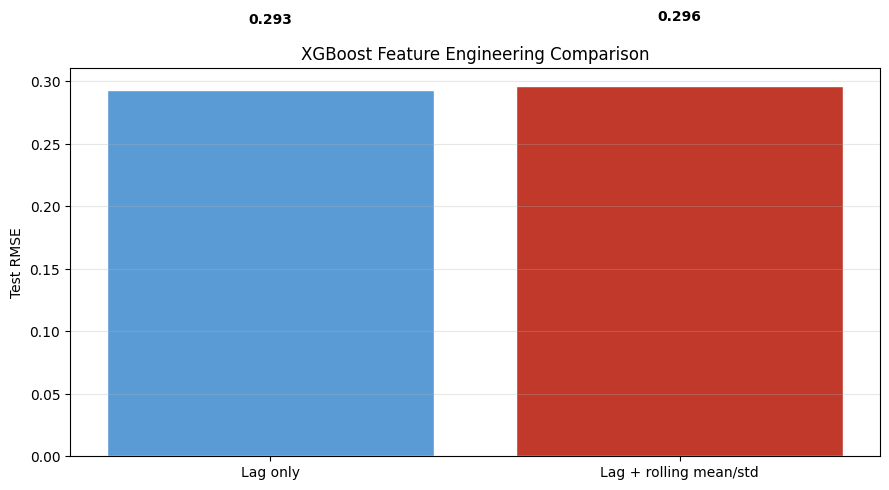

In [26]:
# Compare the two feature engineering choices
comparison = pd.DataFrame({
    'Feature set': ['Lag only', 'Lag + rolling mean/std'],
    'Validation RMSE': [lag_only_result['best_val_rmse'], lag_roll_result['best_val_rmse']],
    'Test RMSE': [lag_only_result['test_rmse'], lag_roll_result['test_rmse']],
    'Test MAE': [lag_only_result['test_mae'], lag_roll_result['test_mae']],
    'Test R2': [lag_only_result['test_r2'], lag_roll_result['test_r2']],
})

print(comparison.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

rmse_delta = lag_only_result['test_rmse'] - lag_roll_result['test_rmse']
if rmse_delta > 0:
    print(f'Rolling features improved test RMSE by {rmse_delta:.4f}.')
elif rmse_delta < 0:
    print(f'Lag-only features were better by {abs(rmse_delta):.4f} RMSE.')
else:
    print('Both feature sets produced the same test RMSE.')

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(comparison['Feature set'], comparison['Test RMSE'], color=['#5b9bd5', '#c0392b'], edgecolor='white')
for bar, value in zip(bars, comparison['Test RMSE']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05, f'{value:.3f}', ha='center', va='bottom', fontweight='bold')
ax.set_title('XGBoost Feature Engineering Comparison')
ax.set_ylabel('Test RMSE')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

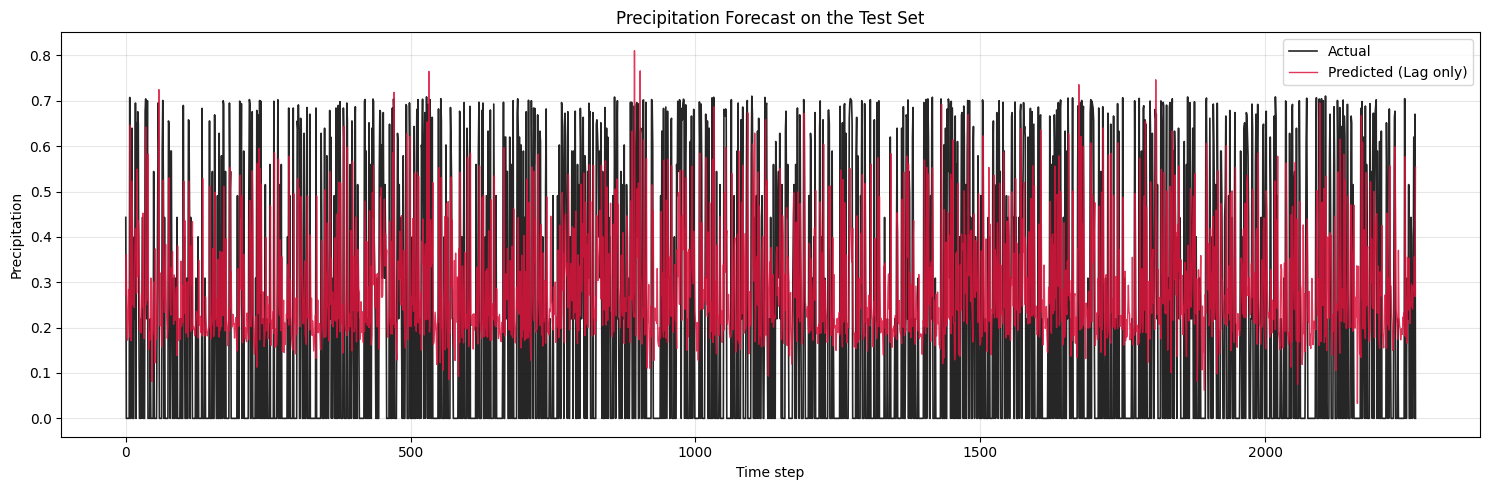

In [27]:
# Plot actual vs predicted for the better feature set
if lag_roll_result['test_rmse'] <= lag_only_result['test_rmse']:
    best_label = 'Lag + rolling mean/std'
    best_actual = y_test_roll
    best_pred = lag_roll_result['test_pred_orig']
else:
    best_label = 'Lag only'
    best_actual = y_test_lag
    best_pred = lag_only_result['test_pred_orig']

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(best_actual, label='Actual', color='black', linewidth=1.2, alpha=0.85)
ax.plot(best_pred, label=f'Predicted ({best_label})', color='crimson', linewidth=1.0, alpha=0.85)
ax.set_title('Precipitation Forecast on the Test Set')
ax.set_xlabel('Time step')
ax.set_ylabel('Precipitation')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()